In [1]:

import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
import glob 

import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from bluemath_tk.datamining import PCA
from sklearn.decomposition import PCA as PCA_
from bluemath_tk.core.operations import spatial_gradient

#### Load Data and Generate Gradient if not calculated Before

In [2]:
data_msl = xr.open_zarr('/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/daily_atmospheric/outputs/data/era5_mslp_grad_1985_2026_1deg_hourly.zarr').rename({'grad2':'msl_gradient'})

#### Training and Testing Years

In [3]:
training = slice('1985-01-01', '2015-12-31')
testing = slice('2016-01-01', '2026-12-31')

#### Set PCA by Covariance solver, not SVD

In [4]:
pca_msl = PCA(n_components=13)
pca_msl._pca = PCA_(n_components=13, svd_solver="covariance_eigh")

pca_msl_gradient = PCA(n_components=50)
pca_msl_gradient._pca = PCA_(n_components=50, svd_solver="covariance_eigh")

2026-11-17 16:57:19,071 - PCA - WARNING - Using PCA
2026-11-17 16:57:19,073 - PCA - WARNING - Using PCA


#### PCA

In [5]:
pca_msl.fit_transform(data=data_msl.sel(valid_time=training), vars_to_stack=['msl'], coords_to_stack=['latitude','longitude'], pca_dim_for_rows='valid_time')
pca_msl_gradient.fit_transform(data=data_msl.sel(valid_time=training), vars_to_stack=['msl_gradient'], coords_to_stack=['latitude','longitude'], pca_dim_for_rows='valid_time')

2026-11-17 16:57:26,607 - PCA - WARNING - Using 1800 out of 1800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-11-17 16:57:54,781 - PCA - WARNING - Using 1800 out of 1800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method


<xarray.Dataset> Size: 57MB
Dimensions:      (valid_time: 271728, n_component: 50)
Coordinates:
  * valid_time   (valid_time) datetime64[ns] 2MB 1985-01-01 ... 2015-12-31T23...
  * n_component  (n_component) int64 400B 0 1 2 3 4 5 6 ... 43 44 45 46 47 48 49
Data variables:
    PCs          (valid_time, n_component) float32 54MB 6.717 18.18 ... 3.817
    stds         (n_component) float32 200B 13.1 10.18 9.124 ... 2.46 2.411

presión: 13 modos para el 95 %  ·  primeros 5 = 82.7 %  ·  10 = 93.5 %
gradiente: > 50 modos (llega al 73.7 %)  ·  primeros 5 = 29.7 %  ·  10 = 42.7 %


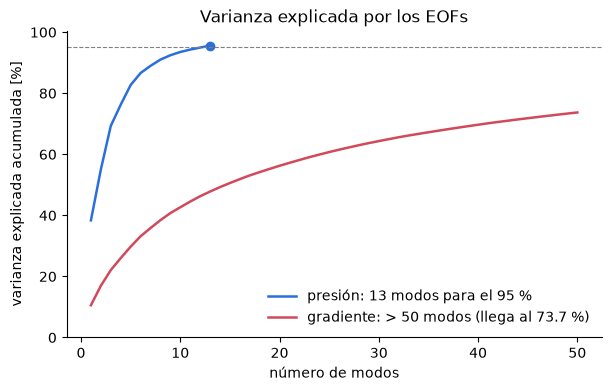

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.8), constrained_layout=True)
for pca, name, c in [(pca_msl, "presión", "#2a6fdb"), (pca_msl_gradient, "gradiente", "#d1495b")]:
    cum = np.cumsum(pca.explained_variance_ratio)
    n = np.arange(1, len(cum) + 1)
    if cum[-1] >= 0.95:
        n95 = int(np.searchsorted(cum, 0.95) + 1)
        label = f"{name}: {n95} modos para el 95 %"
        ax.plot(n95, cum[n95 - 1] * 100, "o", color=c, ms=6)
    else:
        label = f"{name}: > {len(cum)} modos (llega al {cum[-1]*100:.1f} %)"
    ax.plot(n, cum * 100, color=c, lw=1.8, label=label)
    print(f"{label}  ·  primeros 5 = {cum[4]*100:.1f} %  ·  10 = {cum[9]*100:.1f} %")

ax.axhline(95, color="0.5", lw=0.8, ls="--")
ax.set(xlabel="número de modos", ylabel="varianza explicada acumulada [%]", ylim=(0, 100.5),
       title="Varianza explicada por los EOFs")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")

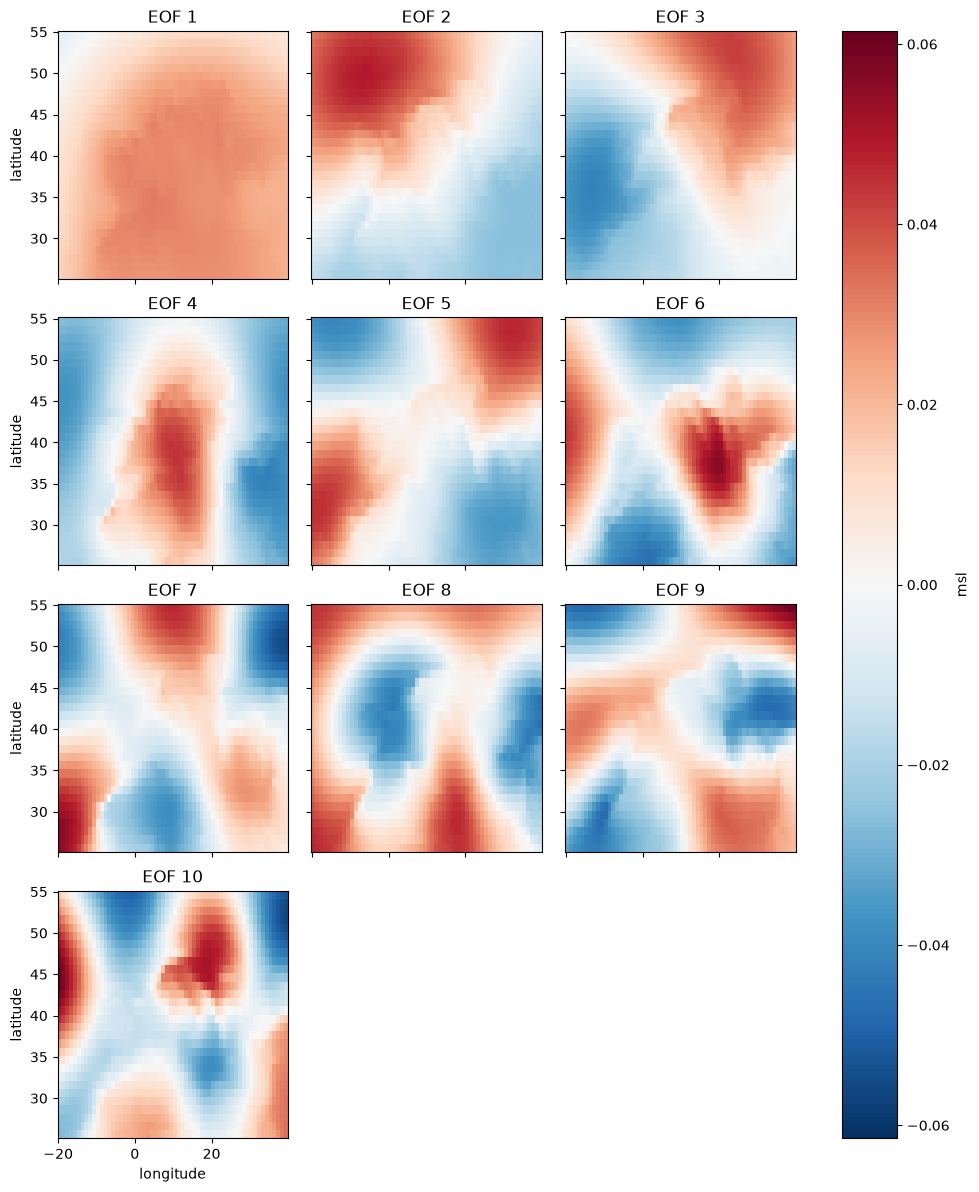

In [7]:
pca_msl.plot_eofs(vars_to_plot=['msl'], num_eofs=10)

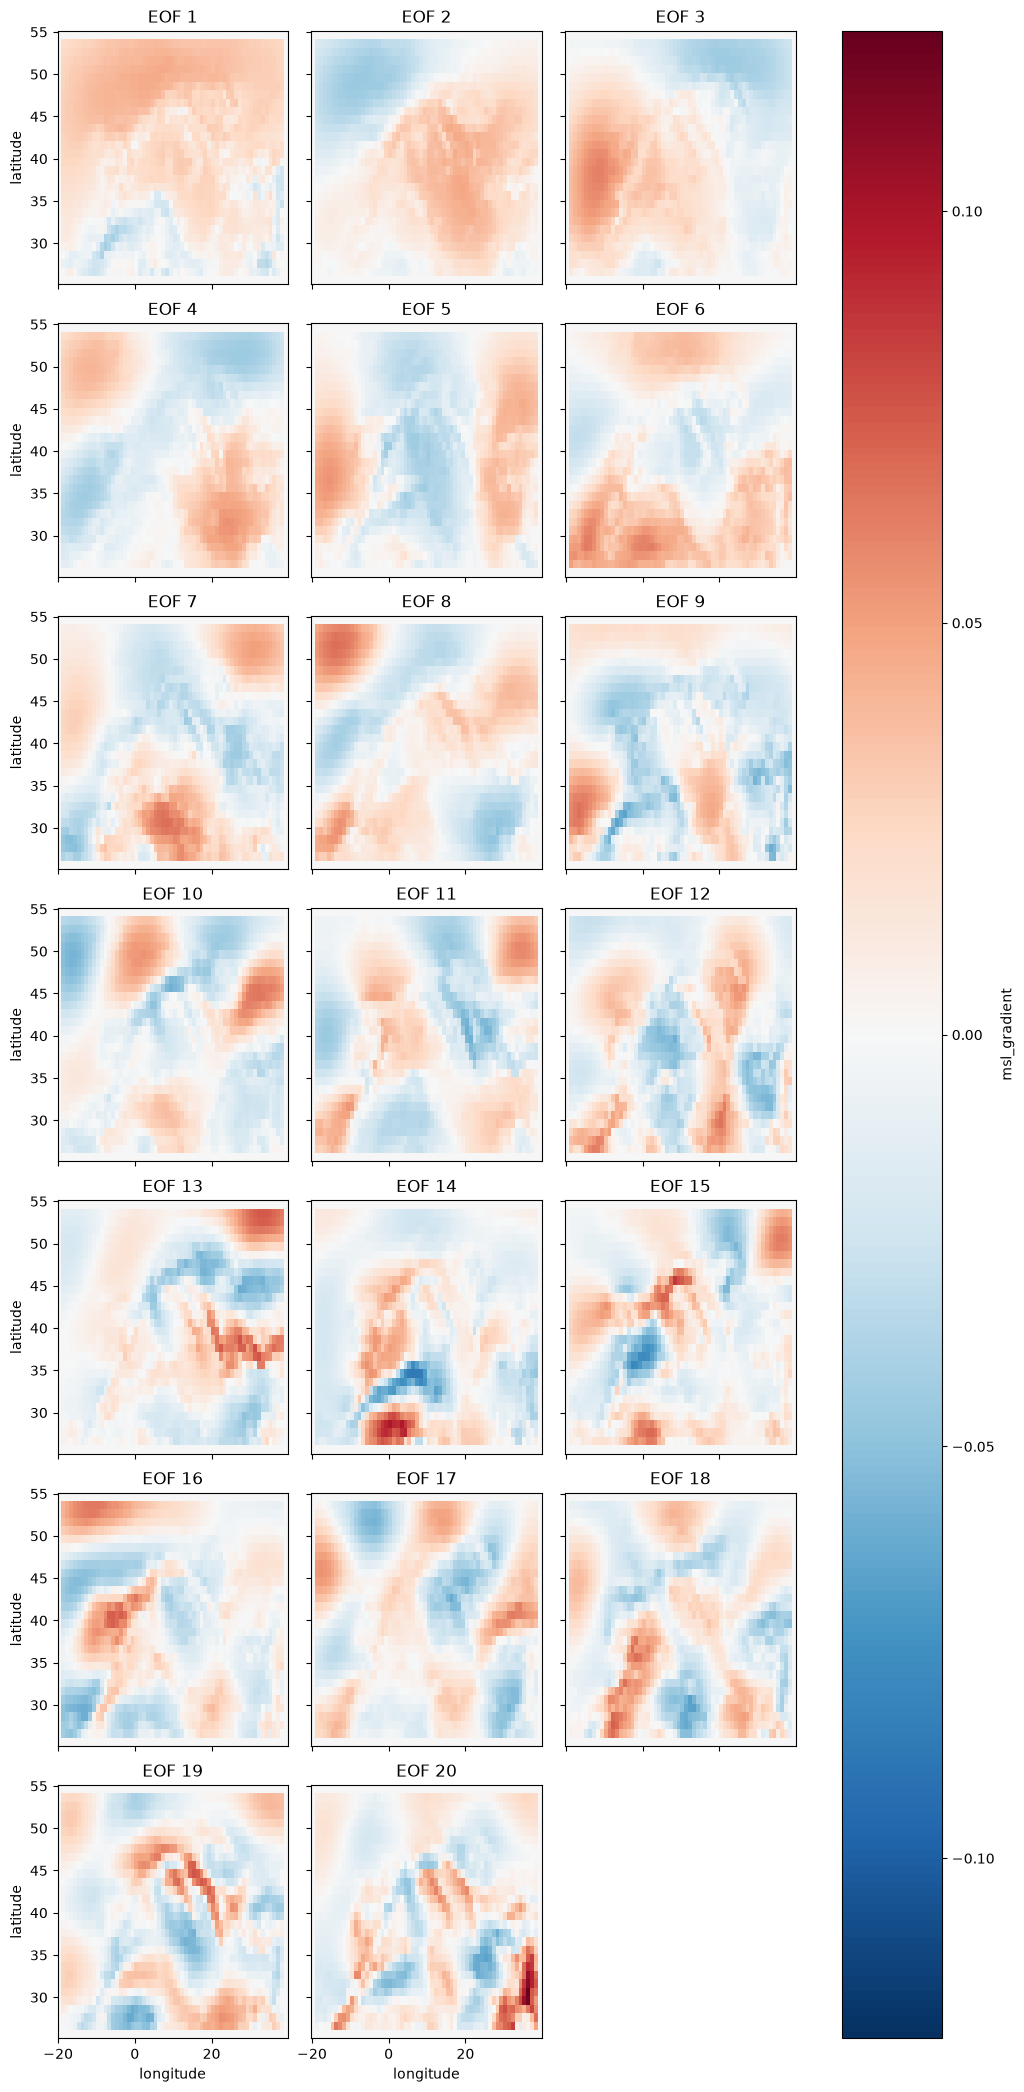

In [8]:
pca_msl_gradient.plot_eofs(vars_to_plot=['msl_gradient'], num_eofs=20)

In [9]:
pcs_msl_nc = pca_msl.transform(data=data_msl)
pcs_msl_gradient_nc = pca_msl_gradient.transform(data=data_msl)

2026-11-17 16:58:42,925 - PCA - WARNING - Using 1800 out of 1800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-11-17 16:59:47,911 - PCA - WARNING - Using 1800 out of 1800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method


In [10]:
pca_dir = '/lustre/geocean/WORK/users/alonsoap/projects/TWINPEACS/02_Emulator_Testing/two_stage_model/outputs/pca'

def guardar(pca_obj, pcs_ds, nombre, prefijo):
    # 1) modelo PCA completo (EOFs, escalado, coordenadas) para proyectar campos nuevos
    pca_obj.save_model(os.path.join(pca_dir, f"pca_{nombre}.pkl"))

    # 2) PCs en netCDF, sin codificación heredada
    pcs_ds = pcs_ds.copy()
    for v in pcs_ds.variables:
        pcs_ds[v].encoding = {}
    f_nc = os.path.join(pca_dir, f"pcs_{nombre}.nc")
    if os.path.exists(f_nc):
        os.remove(f_nc)
    pcs_ds.to_netcdf(f_nc)

    # 3) DataFrame: una columna por PC, índice horario
    df = pd.DataFrame(pcs_ds["PCs"].values,
                      index=pd.DatetimeIndex(pcs_ds["valid_time"].values, name="time"),
                      columns=[f"{prefijo}_PC{i + 1}" for i in range(pcs_ds.sizes["n_component"])])
    df.to_csv(os.path.join(pca_dir, f"pcs_{nombre}.csv"), float_format="%.5f")
    print(f"{nombre}: {df.shape[0]} horas × {df.shape[1]} PCs guardadas en {pca_dir}")
    return df

#pcs_msl_df = guardar(pca_msl, pcs_msl_nc, "msl", "msl")
#pcs_grad_df = guardar(pca_msl_gradient, pcs_msl_gradient_nc, "msl_gradient", "grad")

In [16]:
print(type(pca_msl.pcs_df), pca_msl.pcs_df.index[:2], pca_msl.pcs_df.index[-2:])

<class 'pandas.DataFrame'> DatetimeIndex(['1985-01-01 00:00:00', '1985-01-01 01:00:00'],
              dtype='datetime64[ns]', freq=None) DatetimeIndex(['2015-12-31 22:00:00', '2015-12-31 23:00:00'],
              dtype='datetime64[ns]', freq=None)


In [21]:
from scipy.stats import pearsonr
TIME = pca_msl.pca_dim_for_rows          # "time" o "valid_time", el que usaste
VAR_M = pca_msl.vars_to_stack[0]         # nombre de la variable de presión en el ajuste
VAR_G = pca_msl_gradient.vars_to_stack[0]        # nombre de la variable del gradiente en el ajuste
t_sel = slice("2016-01-01", "2025-12-31")

# --- 1. PCs de presión del test (con todas las componentes del modelo ajustado)
pcs_msl_all = pd.read_csv("outputs/pca/pcs_msl.csv", index_col=0, parse_dates=True)   # <- tu ruta
pcs_m = pcs_msl_all.loc[t_sel]
pcs_da = xr.DataArray(pcs_m.values, dims=(TIME, "n_component"),
                      coords={TIME: pcs_m.index.values,
                              "n_component": np.arange(pcs_m.shape[1])})

# --- 2. Reconstruir presión
rec = pca_msl.inverse_transform(pcs_da)[VAR_M]               # lo mismo que entró al fit
# Si al fit le pasaste anomalías ponderadas, deshazlo exactamente igual:
# rec = rec / w_coslat                                       # <- solo si ponderaste
# rec = rec.groupby(f"{TIME}.dayofyear") + clim_msl          # <- solo si restaste climatología

# --- 3. Gradiente (DataArray, dims en orden time, latitude, longitude)
rec_da = rec.rename({TIME: "time"}).transpose("time", "latitude", "longitude")
grad = spatial_gradient(rec_da).rename({"time": TIME})
# (mismas anomalías / pesos que aplicaste al gradiente antes del fit, si los hubo)

# --- 4. Proyectar con tu PCA del gradiente
pcs_g_rec = pca_msl_gradient.transform(grad.to_dataset(name=VAR_G))["PCs"]
pcs_g_rec = pd.DataFrame(pcs_g_rec.values, index=pcs_m.index,
                         columns=[f"grad_PC{i+1}" for i in range(pcs_g_rec.shape[1])])

# --- 5. Correlación PC a PC con las reales
real = pd.read_csv("outputs/pca/pcs_msl_gradient.csv", index_col=0, parse_dates=True)  # <- PCs completas
real = real.reindex(pcs_g_rec.index)                       # mismas fechas que la reconstrucción
print(real.shape, pcs_g_rec.shape, real.isna().sum().sum())  # comprobación rápida

corr = pd.Series({f"grad_PC{i+1}": pearsonr(real.iloc[:, i], pcs_g_rec.iloc[:, i])[0]
                  for i in range(real.shape[1])})
print(corr.round(2).to_string())

2026-11-17 17:06:16,331 - PCA - WARNING - Using 1800 out of 1800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method


(87672, 50) (87672, 50) 0
grad_PC1     0.95
grad_PC2     0.88
grad_PC3     0.87
grad_PC4     0.79
grad_PC5     0.74
grad_PC6     0.82
grad_PC7     0.71
grad_PC8     0.69
grad_PC9     0.63
grad_PC10    0.64
grad_PC11    0.60
grad_PC12    0.62
grad_PC13    0.65
grad_PC14    0.60
grad_PC15    0.56
grad_PC16    0.45
grad_PC17    0.50
grad_PC18    0.45
grad_PC19    0.55
grad_PC20    0.45
grad_PC21    0.47
grad_PC22    0.44
grad_PC23    0.51
grad_PC24    0.47
grad_PC25    0.44
grad_PC26    0.42
grad_PC27    0.41
grad_PC28    0.46
grad_PC29    0.40
grad_PC30    0.44
grad_PC31    0.37
grad_PC32    0.43
grad_PC33    0.39
grad_PC34    0.37
grad_PC35    0.43
grad_PC36    0.45
grad_PC37    0.50
grad_PC38    0.29
grad_PC39    0.35
grad_PC40    0.36
grad_PC41    0.43
grad_PC42    0.46
grad_PC43    0.44
grad_PC44    0.33
grad_PC45    0.37
grad_PC46    0.40
grad_PC47    0.35
grad_PC48    0.32
grad_PC49    0.35
grad_PC50    0.36


In [22]:
pcs_g_rec.to_csv("/nfs/home/geocean/alonsoap/pcs_grad_reconstruido_13msl.csv")